# Customer Retention Intelligence — Model Explainability (SHAP)

## Objective
Explain the **Phase 7 tuned Logistic Regression** (`C=0.01`,
`class_weight="balanced"`) for `churn_next_30_days`, using SHAP:

1. Which features generally drive churn predictions (global importance).
2. Why an individual customer is predicted high/low risk (local explanations).
3. Whether important features push predicted risk up or down.

**This notebook does not retrain, retune, or otherwise change the Phase 7
model.** It loads the frozen `models/tuned_logistic_regression.joblib`
pipeline and only explains it. All explainability logic lives in
`src/models/explainability.py`; this notebook calls it, inspects results,
and saves the required report artifacts.

**SHAP method:** `shap.LinearExplainer` -- the exact (non-sampling)
explainer for linear models. For Logistic Regression, SHAP values are
additive and exact: `base_value + sum(shap_values)` reconstructs the
model's linear output for that row, whose sigmoid is `predict_proba`.
This is verified directly in
`tests/test_explainability.py::test_shap_values_reconstruct_predicted_probability`.

All SHAP computations use the **VALIDATION** split (consistent with the
validation-only philosophy already established in Phase 7); the TEST
split is not read anywhere in this notebook.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

from src.models import baseline as bl
from src.models import explainability as ex

PROJECT_ROOT

PosixPath('/Users/dhananjaymandal/customer-retention-intelligence')

## 1. Load the Frozen Phase 7 Model

`load_tuned_pipeline` refuses to proceed if the loaded model's
hyperparameters don't match the Phase 7 selection (`C=0.01`,
`class_weight="balanced"`) -- a defensive check against ever explaining
the wrong artifact.

In [2]:
pipeline = ex.load_tuned_pipeline()
model = pipeline.named_steps["model"]
print(pipeline)
print(f"\nC={model.C}, class_weight={model.class_weight}, n_coefficients={model.coef_.shape[1]}")

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'tenure_days',
                                                   'tenure_months',
                                                   'txn_count_30d',
                                                   'txn_amount_sum_30d',
                                                   'txn_amount_mean_30d',
                                                   'txn_amount_max_30d',
                                                   'txn_success_count_30d',
                                                   'txn_

## 2. Load Data and Reproduce the Chronological Split

Same Phase 4 feature dataset and Phase 5 split used throughout every
prior phase.

In [3]:
features = bl.load_feature_dataset()
splits = bl.split_by_snapshot_date(features)
numeric_columns, categorical_columns = bl.get_feature_columns(features)
feature_columns = numeric_columns + categorical_columns

X_train = splits["train"][feature_columns]
X_val = splits["validation"][feature_columns]

print(f"train={len(X_train)}, validation={len(X_val)}, features={len(feature_columns)}")

train=85419, validation=26337, features=131


## 3. Feature Name Mapping

The pipeline's `ColumnTransformer` prefixes every output column with its
transformer's name (`numeric__...` / `categorical__...`). `build_feature_metadata`
strips that prefix and, for one-hot categorical columns, recovers the
original column and category (e.g. `categorical__plan_Premium` ->
`origin_column="plan"`, `category="Premium"`) so SHAP values can be
reported against understandable names and a customer's actual raw value,
never an opaque transformed column name.

In [4]:
preprocessor = pipeline.named_steps["preprocessor"]
feature_metadata = ex.build_feature_metadata(preprocessor, categorical_columns)
display_names = feature_metadata["display_name"].tolist()

print(f"{len(feature_metadata)} transformed features "
      f"({len(numeric_columns)} numeric + {len(feature_metadata) - len(numeric_columns)} one-hot categorical levels)")
feature_metadata.head(10)

142 transformed features (127 numeric + 15 one-hot categorical levels)


,transformed_name,display_name,kind,origin_column,category
0,numeric__age,age,numeric,age,NaN
1,numeric__tenure_days,tenure_days,numeric,tenure_days,NaN
2,numeric__tenure_months,tenure_months,numeric,tenure_months,NaN
3,numeric__txn_count_30d,txn_count_30d,numeric,txn_count_30d,NaN
4,numeric__txn_amount_sum_30d,txn_amount_sum_30d,numeric,txn_amount_sum_30d,NaN
5,numeric__txn_amount_mean_30d,txn_amount_mean_30d,numeric,txn_amount_mean_30d,NaN
6,numeric__txn_amount_max_30d,txn_amount_max_30d,numeric,txn_amount_max_30d,NaN
7,numeric__txn_success_count_30d,txn_success_count_30d,numeric,txn_success_count_30d,NaN
8,numeric__txn_failed_count_30d,txn_failed_count_30d,numeric,txn_failed_count_30d,NaN
9,numeric__txn_purchase_count_30d,txn_purchase_count_30d,numeric,txn_purchase_count_30d,NaN


## 4. Build the SHAP Explainer

The background (SHAP's reference point) is a fixed-seed sample of
**TRAIN only**, transformed with the already-fitted preprocessor --
consistent with every leakage rule from Phases 5-7. Sampling from
validation/test here would leak their distribution into the very
reference point every SHAP value is computed relative to.

In [5]:
background = ex.build_background(preprocessor, X_train)
explainer = ex.build_explainer(pipeline, background)
print(f"Background shape: {background.shape} (sampled from TRAIN, seed={bl.RANDOM_SEED})")

Background shape: (100, 142) (sampled from TRAIN, seed=42)


## 5. Compute SHAP Values (Validation Split)

In [6]:
shap_values = ex.compute_shap_values(explainer, preprocessor, X_val, display_names)
print(f"SHAP values shape: {shap_values.values.shape}")
assert not np.isnan(shap_values.values).any()
assert not np.isinf(shap_values.values).any()
print("No NaN/inf SHAP values.")

SHAP values shape: (26337, 142)
No NaN/inf SHAP values.


## 6. Global Feature Importance

Mean absolute SHAP value per feature (direction-agnostic overall
importance) and mean signed SHAP value (average direction of effect),
ranked and saved to `reports/shap_feature_importance.csv`.

In [7]:
importance = ex.global_feature_importance(shap_values)
importance_path = ex.save_feature_importance(importance)
print(f"Saved -> {importance_path}")
importance.head(20)

Saved -> /Users/dhananjaymandal/customer-retention-intelligence/reports/shap_feature_importance.csv


,feature,mean_abs_shap,mean_shap,rank
0,avg_pages_viewed_90d,0.426808,-0.016501,1
1,active_days_90d,0.380876,0.231281,2
2,avg_active_minutes_90d,0.262517,0.005053,3
3,avg_feature_usage_count_previous30d,0.250474,0.012438,4
4,avg_active_minutes_previous30d,0.239731,0.001016,5
5,txn_amount_sum_180d,0.231411,-0.101709,6
6,avg_session_minutes_previous30d,0.225271,-0.005626,7
7,avg_pages_viewed_recent30d,0.213281,0.013962,8
8,txn_amount_sum_90d,0.201153,0.091927,9
9,avg_login_count_90d,0.195589,-0.015239,10


## 7. SHAP Summary Bar Plot (Top 20)

Overall importance -- mean absolute SHAP value per feature.

Saved -> /Users/dhananjaymandal/customer-retention-intelligence/reports/figures/shap_global_bar.png


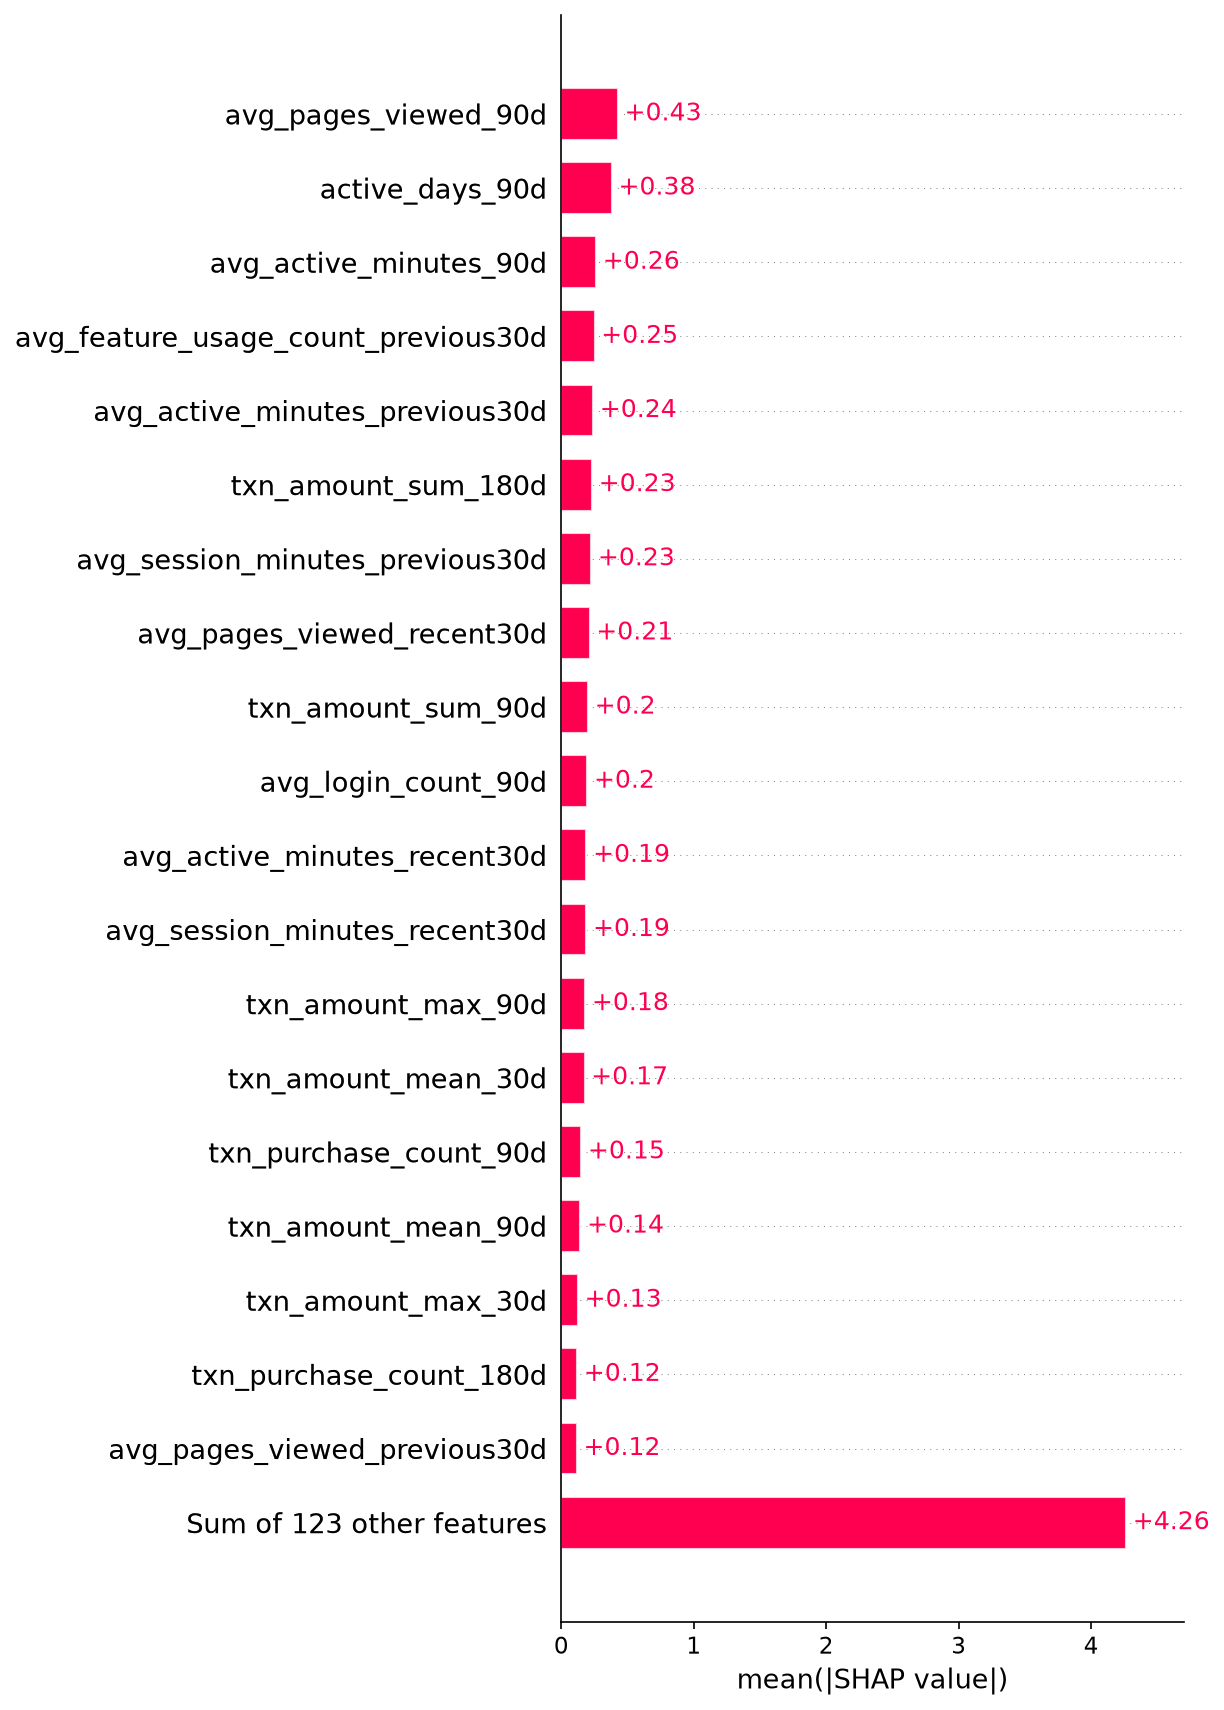

In [8]:
from IPython.display import Image

bar_path = ex.plot_global_bar(shap_values, save_path=ex.FIGURES_DIR / "shap_global_bar.png")
print(f"Saved -> {bar_path}")
Image(filename=str(bar_path))

## 8. SHAP Beeswarm Plot (Top 20)

Importance **and** direction together: each dot is one validation
customer, colored by that customer's own raw feature value (red = high,
blue = low), positioned by that feature's SHAP value for them. This is
the plot that shows whether a feature pushes risk up or down, and for
which customers.

Saved -> /Users/dhananjaymandal/customer-retention-intelligence/reports/figures/shap_global_beeswarm.png


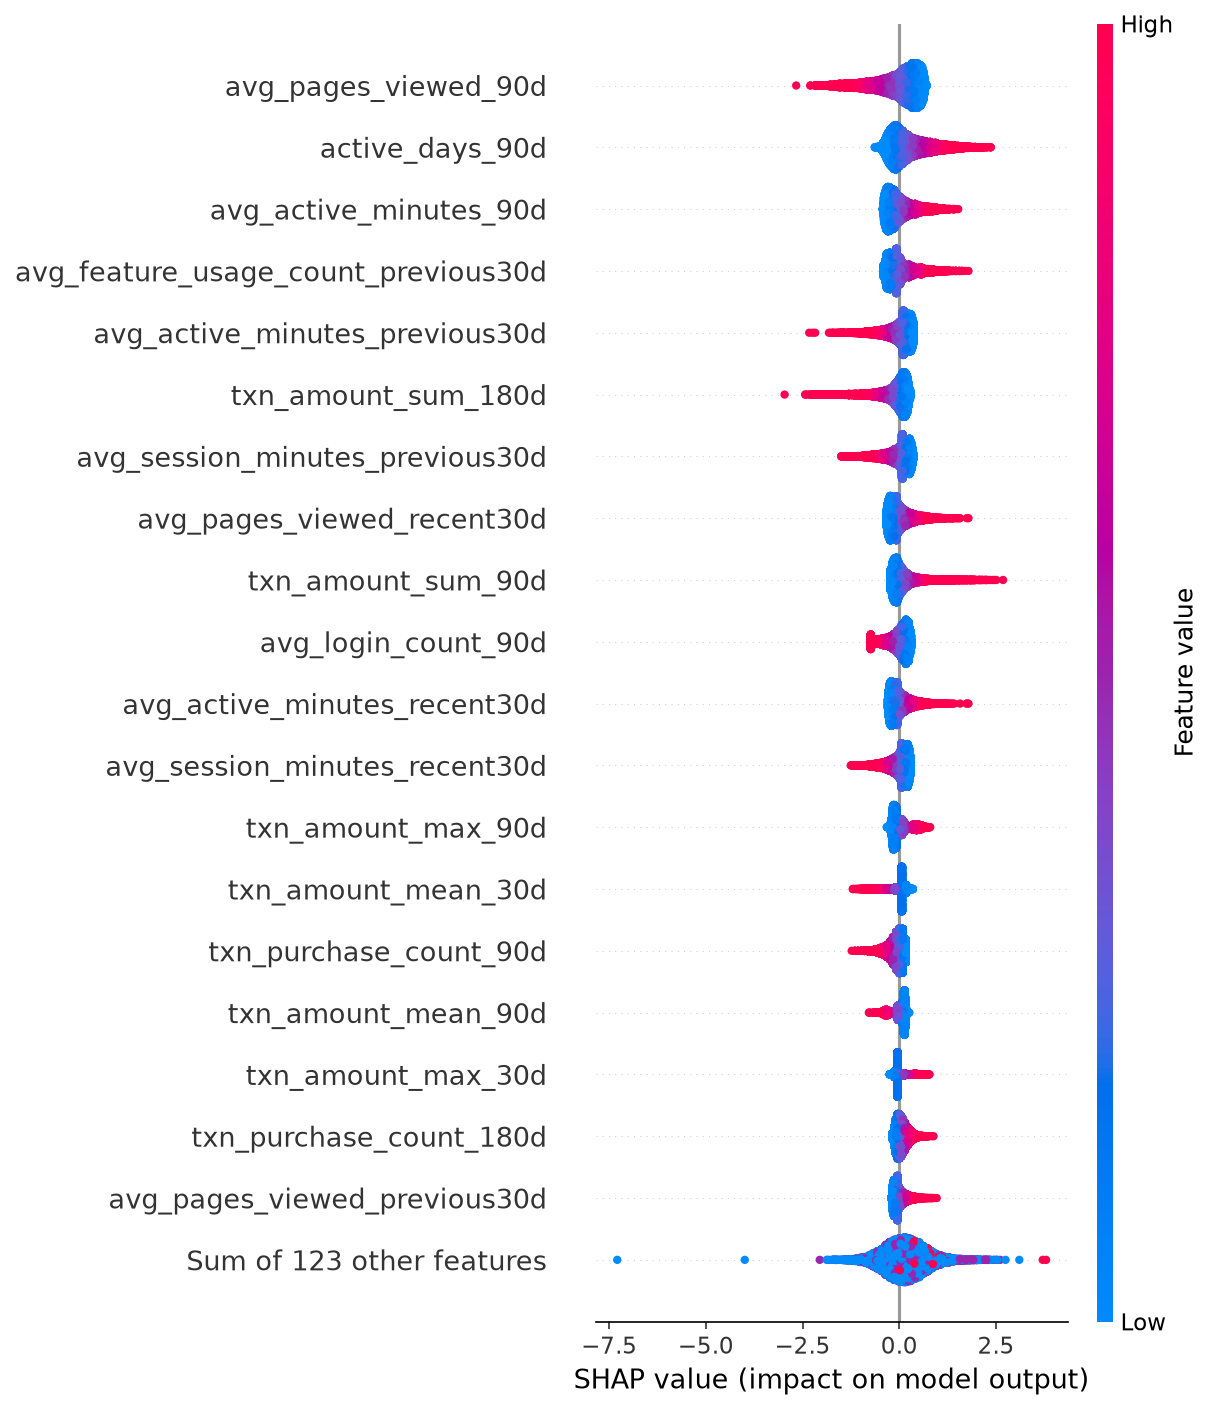

In [9]:
beeswarm_path = ex.plot_global_beeswarm(shap_values, save_path=ex.FIGURES_DIR / "shap_global_beeswarm.png")
print(f"Saved -> {beeswarm_path}")
Image(filename=str(beeswarm_path))

## 9. Individual Prediction Explanations

Three representative validation customers, chosen by **predicted
probability** (not the true label, which stays unseen by this selection):
the highest-probability, median-probability, and lowest-probability
customer. Risk tiers (High/Medium/Low) are assigned from validation
probability terciles -- a labeling convenience for this report, distinct
from the model's actual 0.5 decision threshold used in Phases 5-7.

In [10]:
validation_probabilities = pipeline.predict_proba(X_val)[:, 1]
risk_tier_bounds = ex.compute_risk_tier_bounds(validation_probabilities)
print(f"Risk tier bounds (33rd/66th percentile of validation probabilities): {risk_tier_bounds}")

representative_positions = ex.select_representative_customers(pipeline, X_val)
representative_positions

Risk tier bounds (33rd/66th percentile of validation probabilities): (0.4800482691582983, 0.5973674682031799)


{'high': 17516, 'medium': 17438, 'low': 3332}

In [11]:
representative_explanations = {}
for tier, position in representative_positions.items():
    customer_row = X_val.iloc[[position]]
    explanation = ex.explain_customer(
        pipeline, explainer, customer_row, feature_metadata, risk_tier_bounds=risk_tier_bounds
    )
    explanation["customer_id"] = splits["validation"].iloc[position]["customer_id"]
    explanation["actual_label"] = int(splits["validation"].iloc[position][bl.TARGET_COLUMN])
    representative_explanations[tier] = explanation

    print(f"\n=== {tier.upper()}-RISK customer {explanation['customer_id']} ===")
    print(f"Predicted probability : {explanation['predicted_probability']:.4f}")
    print(f"Risk tier             : {explanation['risk_tier']}")
    print(f"Predicted class (>=0.5): {explanation['predicted_class']}")
    print(f"Actual label (unseen by selection): {explanation['actual_label']}")
    print("Top risk-RAISING drivers:")
    for d in explanation["top_positive_drivers"]:
        print(f"    {d['feature']:35s} shap={d['shap_value']:+.4f}  customer_value={d['customer_value']}")
    print("Top risk-LOWERING (protective) drivers:")
    for d in explanation["top_negative_drivers"]:
        print(f"    {d['feature']:35s} shap={d['shap_value']:+.4f}  customer_value={d['customer_value']}")


=== HIGH-RISK customer C006665 ===
Predicted probability : 0.9732
Risk tier             : High
Predicted class (>=0.5): 1
Actual label (unseen by selection): 0
Top risk-RAISING drivers:
    active_days_90d                     shap=+1.7813  customer_value=54.0
    pending_ticket_count_90d            shap=+0.7582  customer_value=3.0
    resolved_ticket_count_180d          shap=+0.7561  customer_value=16.0
    category_account_count_180d         shap=+0.5923  customer_value=4.0
    category_login_count_180d           shap=+0.5726  customer_value=4.0
Top risk-LOWERING (protective) drivers:
    resolved_ticket_count_90d           shap=-0.9731  customer_value=11.0
    max_resolution_hours_90d            shap=-0.6382  customer_value=310.38
    txn_purchase_count_90d              shap=-0.5712  customer_value=9.0
    category_billing_count_90d          shap=-0.4803  customer_value=4.0
    pending_ticket_count_180d           shap=-0.4440  customer_value=3.0

=== MEDIUM-RISK customer C006637 ===

## 10. Waterfall Plots for Each Representative Customer

Each waterfall shows exactly how that customer's predicted log-odds is
built up from the SHAP base value plus each feature's individual push,
using only the same LinearExplainer output shown as text above.

In [12]:
waterfall_paths = {}
for tier, position in representative_positions.items():
    customer_row = X_val.iloc[[position]]
    transformed = preprocessor.transform(customer_row)
    single_explanation = explainer(transformed)
    single_explanation.feature_names = display_names

    save_path = ex.FIGURES_DIR / f"shap_waterfall_{tier}_risk.png"
    ex.plot_local_waterfall(single_explanation[0], save_path=save_path)
    waterfall_paths[tier] = save_path
    print(f"Saved {tier}-risk waterfall -> {save_path}")

Saved high-risk waterfall -> /Users/dhananjaymandal/customer-retention-intelligence/reports/figures/shap_waterfall_high_risk.png


Saved medium-risk waterfall -> /Users/dhananjaymandal/customer-retention-intelligence/reports/figures/shap_waterfall_medium_risk.png


Saved low-risk waterfall -> /Users/dhananjaymandal/customer-retention-intelligence/reports/figures/shap_waterfall_low_risk.png


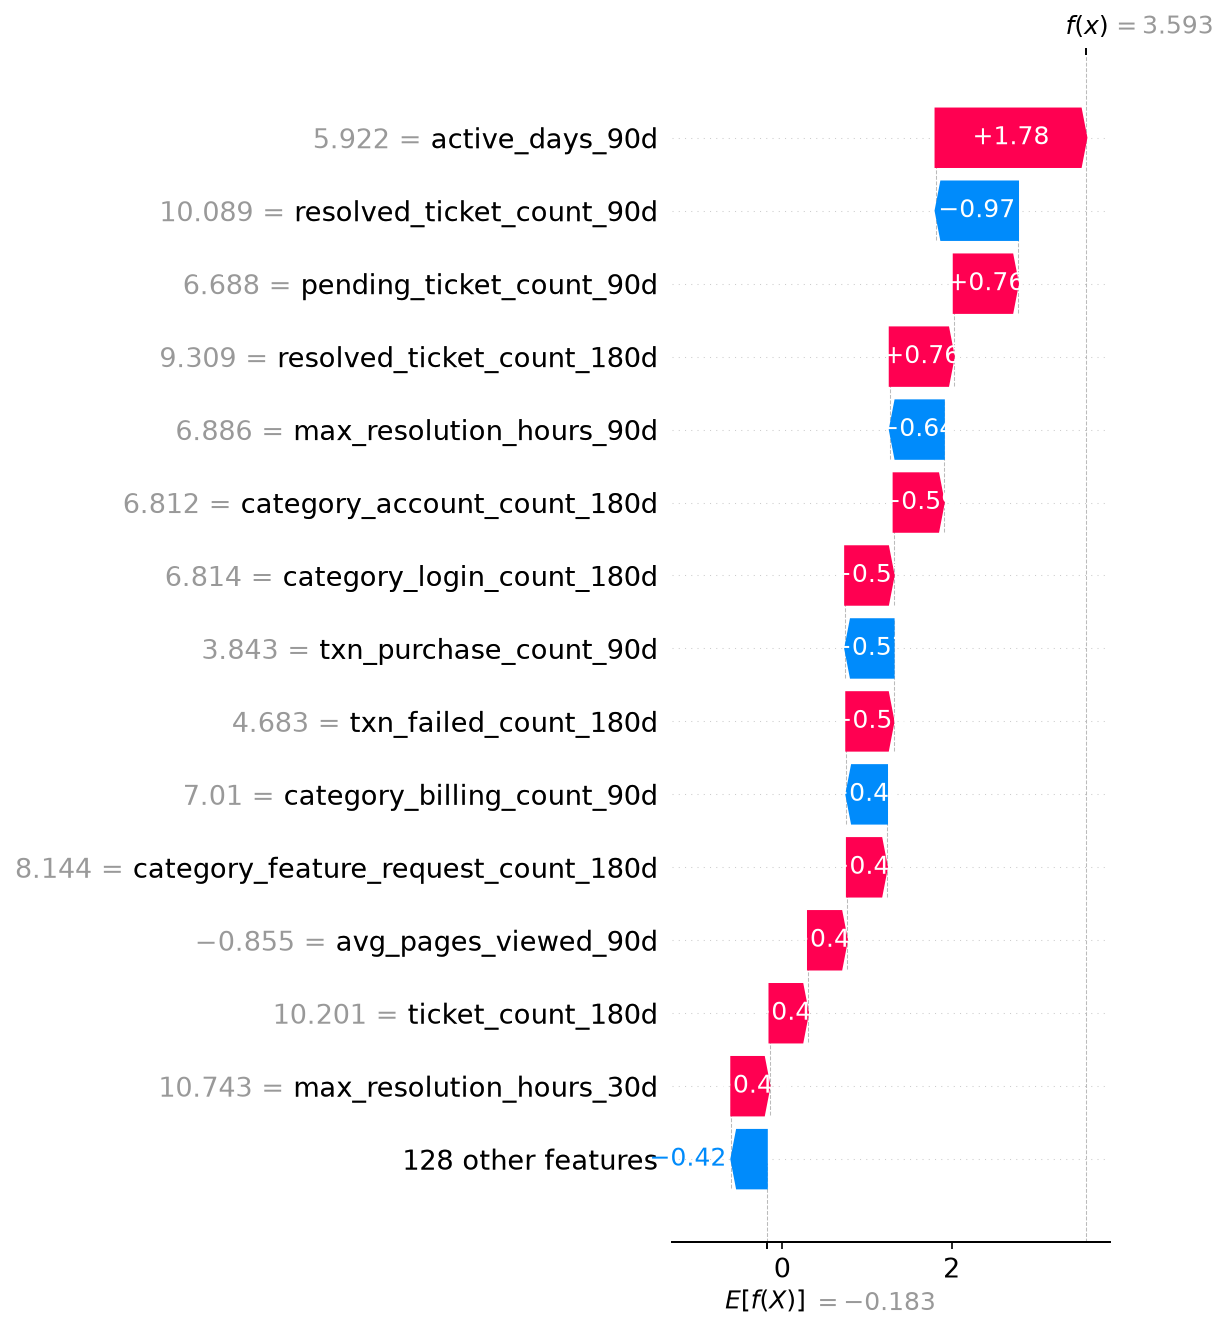

In [13]:
display(Image(filename=str(waterfall_paths["high"])))

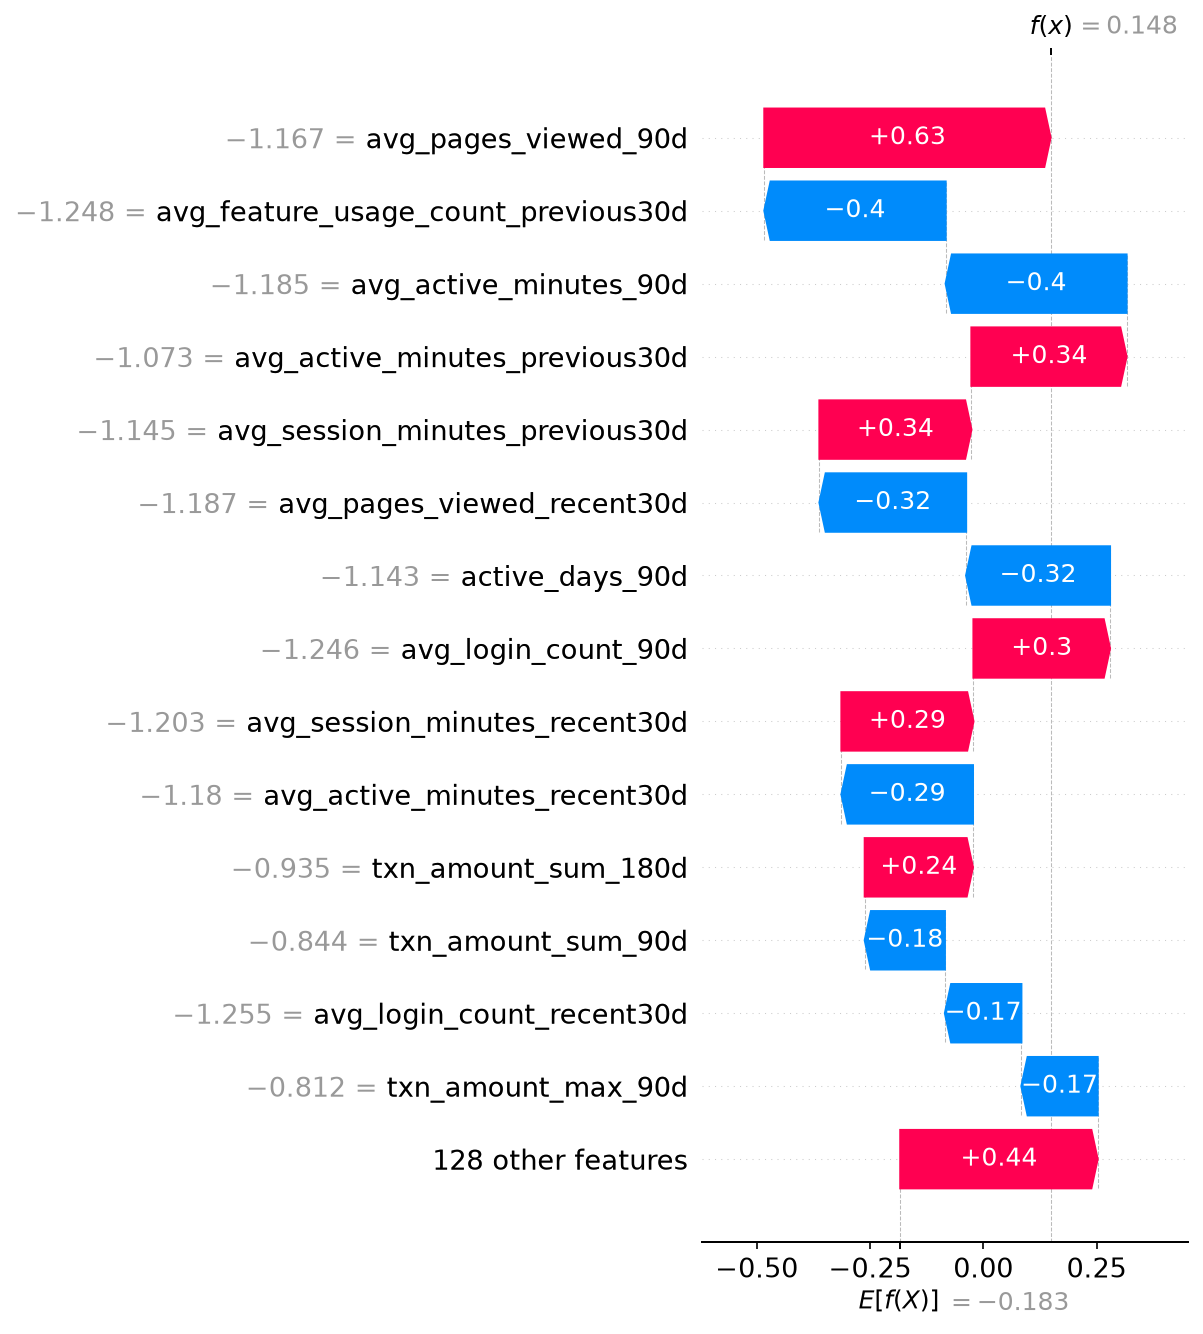

In [14]:
display(Image(filename=str(waterfall_paths["medium"])))

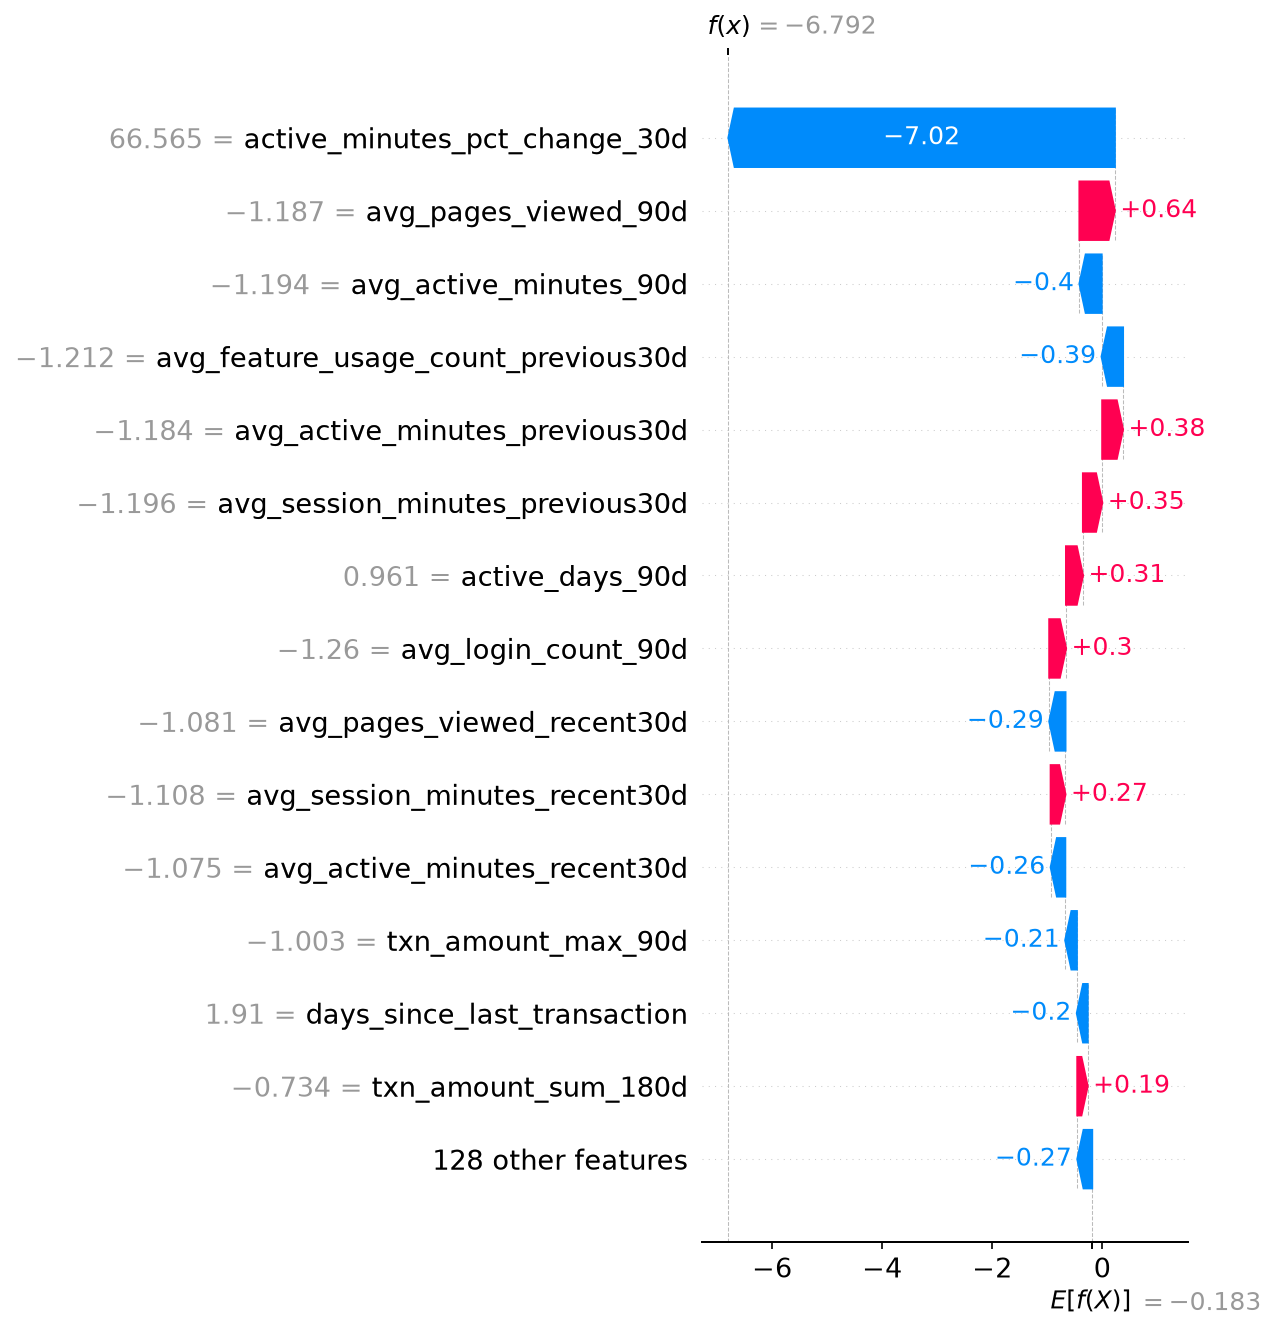

In [15]:
display(Image(filename=str(waterfall_paths["low"])))

## 11. Business Interpretation

Read directly off the global importance table and beeswarm plot above
(Sections 6-8) -- every statement below is an **observed association** in
this model on this validation split, not a claim about what causes churn.
The model cannot distinguish correlation from causation, and neither can
this notebook.

**Top drivers by mean |SHAP value|** (see the printed table for exact
ranks/values, which can shift slightly if the model or data changes):

- **Engagement/activity features dominate the top of the ranking**
  (`avg_pages_viewed_90d`, `active_days_90d`, `avg_active_minutes_90d`,
  session/login features). This says the model relies heavily on recent
  usage intensity to separate predicted risk -- consistent with churn
  being fundamentally about disengagement in this dataset.
- **Transaction-recency and -volume features** (`txn_amount_sum_180d`,
  `txn_amount_sum_90d`, `txn_purchase_count_90d`) also rank highly,
  indicating recent spend/purchase behavior materially shifts predicted
  risk, in both directions depending on the customer.
- Some directions of effect are **not the intuitive "more engagement =
  lower risk" story** -- for example `active_days_90d` has a *positive*
  mean SHAP value in this run, meaning higher values are, on average,
  associated with *higher* predicted risk here. This is reported exactly
  as the model shows it rather than adjusted to match an assumed
  narrative; it may reflect how this project's synthetic data was
  generated, or a genuine (if counter-intuitive) pattern the model found.
  Any operational use of this finding should be validated against real
  business knowledge before being trusted.
- One example customer's protective driver
  (`active_minutes_pct_change_30d`) took an extreme value (tens of
  thousands of percent), driving an outsized SHAP contribution. This is a
  known sensitivity of percent-change features to small denominators and
  is flagged here as a limitation, not a newly discovered strong effect.

**Caveats:**
- Logistic Regression's SHAP values reflect a *linear, additive* model of
  the (already scaled/encoded) features -- any real nonlinear or
  interaction effects in the underlying churn process are not capturable
  by this explanation, only by the model itself (which is itself linear).
- Feature importance here is specific to the Phase 7 model and the
  validation window (2025-12-31 to 2026-02-28); it is not guaranteed to
  hold on future data.
- Association, not causation: nothing here justifies "changing X will
  reduce churn" without a controlled experiment.

## 12. Outputs Saved

- `reports/shap_feature_importance.csv` -- global feature, mean |SHAP|, mean SHAP, rank.
- `reports/figures/shap_global_bar.png` -- top-20 global importance bar chart.
- `reports/figures/shap_global_beeswarm.png` -- top-20 SHAP summary (importance + direction).
- `reports/figures/shap_waterfall_{high,medium,low}_risk.png` -- local explanations for three representative customers.

No files under `models/` are created or modified by this notebook --
Phase 7's `tuned_logistic_regression.joblib` is only ever loaded, never
rewritten.

In [16]:
import os
print("reports/shap_feature_importance.csv exists:", (PROJECT_ROOT / "reports" / "shap_feature_importance.csv").exists())
print("reports/figures/ contents:")
for p in sorted((PROJECT_ROOT / "reports" / "figures").glob("*.png")):
    print(" ", p.name, f"({p.stat().st_size} bytes)")

reports/shap_feature_importance.csv exists: True
reports/figures/ contents:
  shap_global_bar.png (161155 bytes)
  shap_global_beeswarm.png (196640 bytes)
  shap_waterfall_high_risk.png (147165 bytes)
  shap_waterfall_low_risk.png (155484 bytes)
  shap_waterfall_medium_risk.png (152955 bytes)
